In [80]:
using VoronoiMeshes, NCDatasets, DelaunayTriangulation, CairoMakie
include("juliaDEC.jl");

------Solving linear system for edge 14-----
Residuals: 0.0003399716888509646
Rank: 12
Condition number: 977.4842632591217
----------------------------------
Interpolation coefs: [-0.9872250508582391, 0.011536164524454414, 0.7041698644751165, 0.5426708373912417, 0.5483304461157443, 0.6903212480370202, 18.83037508809671, -0.4343888581090284, 18.28761405730579, -0.21719443049304085, 36.78444930365119, -0.2135818934345122]

Error of LSQ Hodge:
9.359657940719718e-5

Value of primal cochain in edge 14: 0.08140443615561442

Value of dual cochain in edge 14: 0.03424109077172997


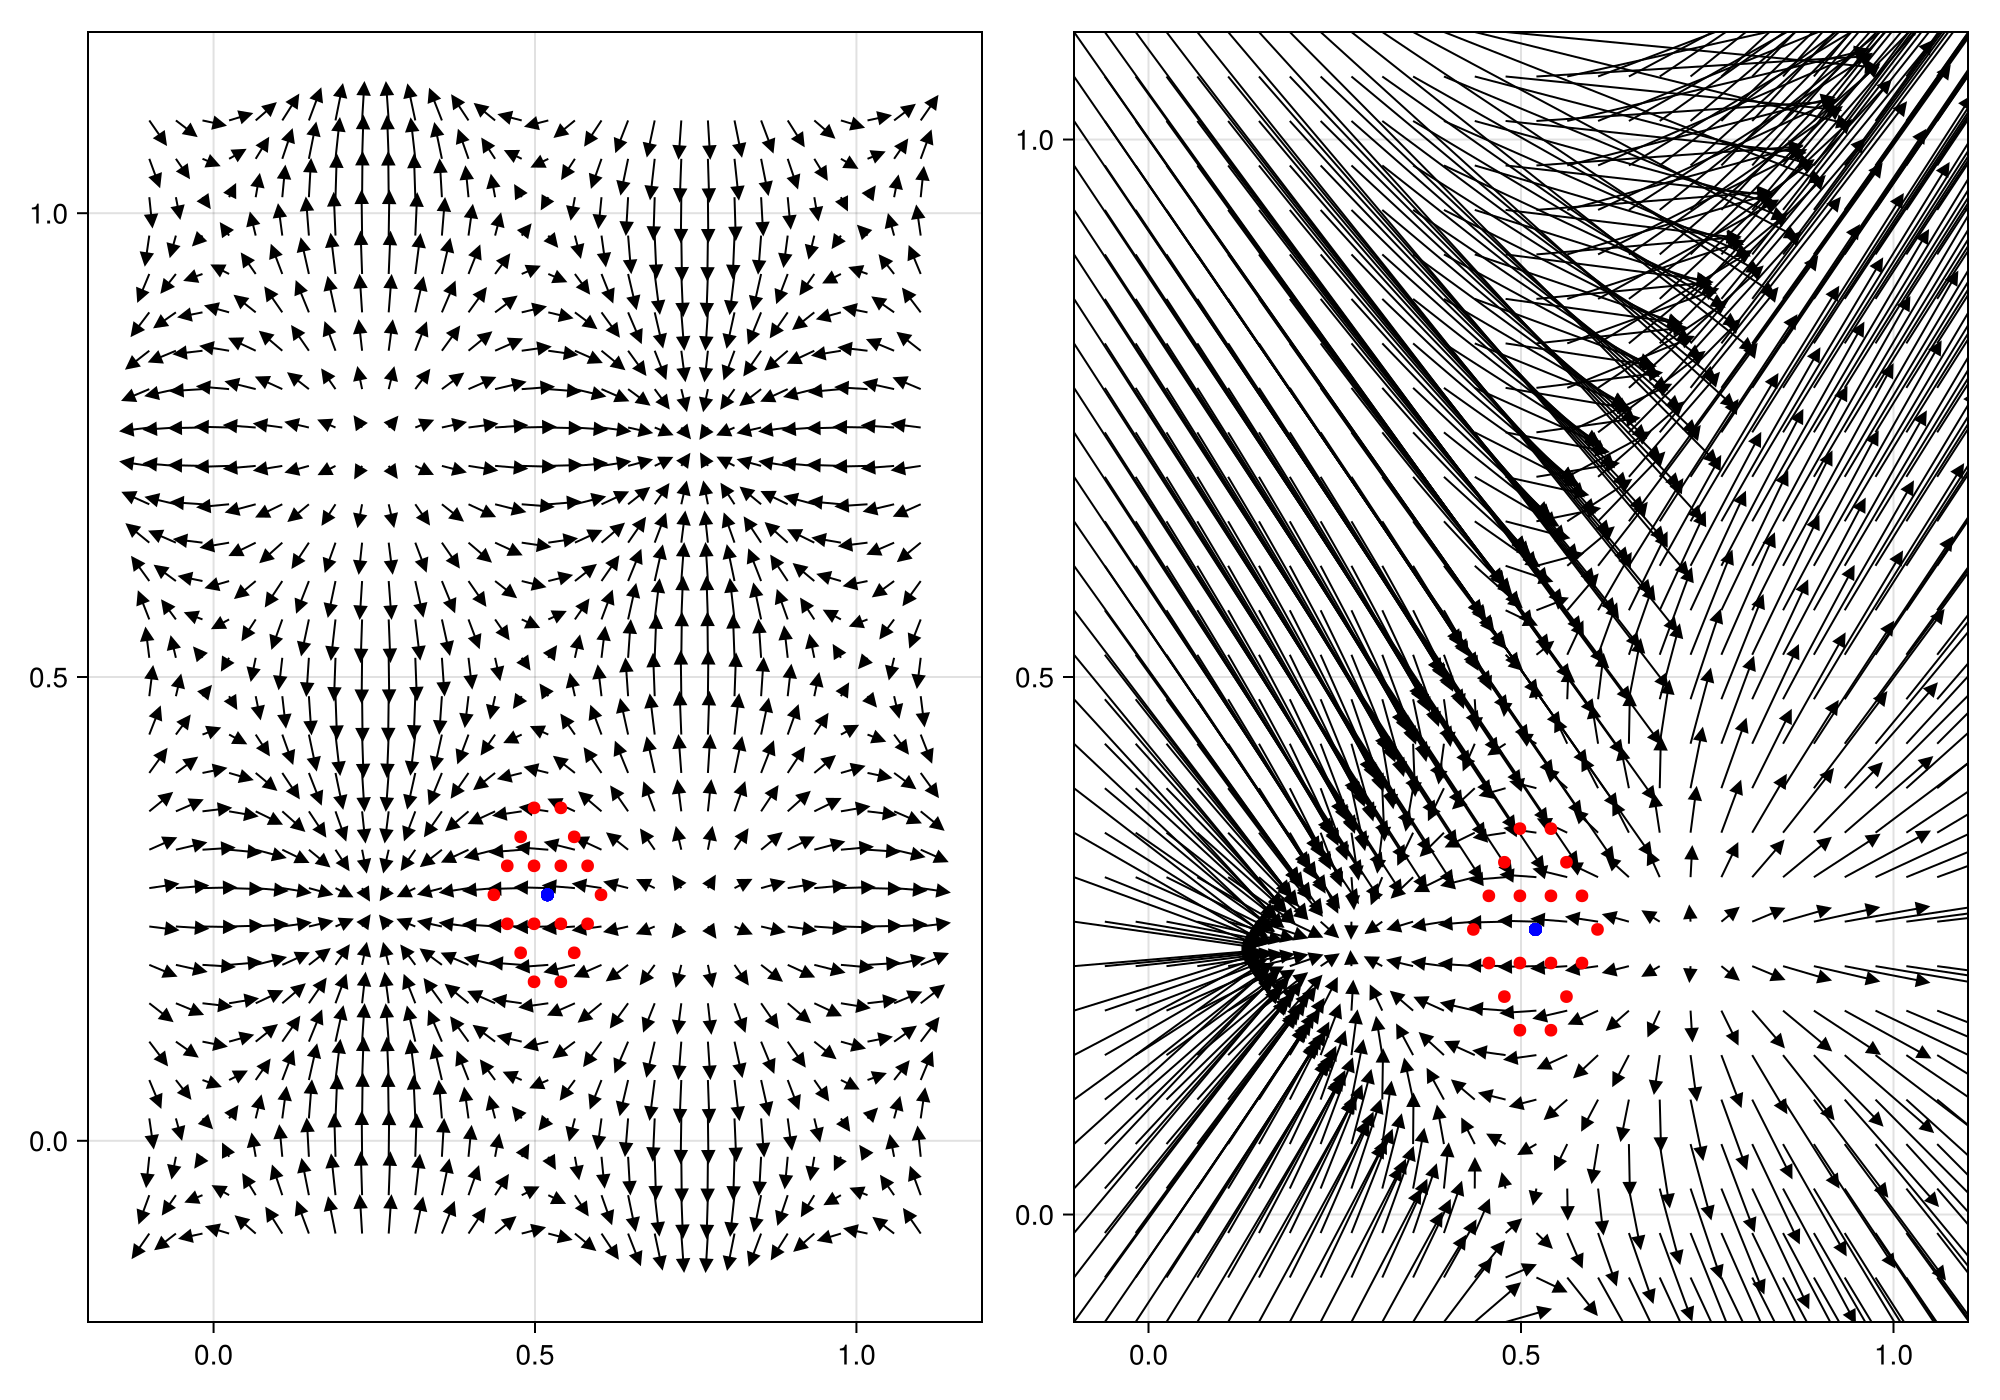

In [2]:
edge_idx = 14
mesh = VoronoiMesh("meshes/mesh3_regular.nc")
xp = mesh.x_period
yp = mesh.y_period


v = discretize_vector_field_dual(mesh, x -> [cos(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp), sin(2*pi*x[1]/xp) * cos(2*pi*x[2]/yp)])
v_dual = discretize_vector_field_primal(mesh, x -> [-sin(2*pi*x[1]/xp) * cos(2*pi*x[2]/yp), cos(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)])
rec_field, coefs, _ = rec_vector_field_lsq_13point(mesh, v, edge_idx , verbose=true, primal_to_dual=true, hodge=false, only_linear=false)
println("Interpolation coefs: ", coefs)
rec_values = integrate_lsq_reconstruction(mesh, v, true, false)

# Checking for the error of the interpolation
# println(maximum(abs.(rec_values.values - v_dual.values)))

println("\nError of LSQ Hodge:")
println(maximum(abs.(hodge_star_lsq_matrix(mesh, true, false) * v.values - v_dual.values)))

println("\nValue of primal cochain in edge $edge_idx: ", v.values[edge_idx])
println("\nValue of dual cochain in edge $edge_idx: ", v_dual.values[edge_idx])

f = Figure(size = (1000, 700))
ax = Axis(f[1, 1])


xs = LinRange(-0.1, 1.1, 30)
ys = LinRange(-0.1, 1.1, 30)
us = [cos(2*pi*x/xp) * sin(2*pi*y/yp) for x in xs, y in ys]
vs = [sin(2*pi*x/xp) * cos(2*pi*y/yp) for x in xs, y in ys]
arrows!(xs, ys, us, vs,arrowsize = 10, lengthscale = 0.04)
neighbors = get_neighbors_3level_primal(mesh, edge_idx)
for neighbor in neighbors
  if neighbor != edge_idx
      scatter!(ax, [mesh.edges.position[neighbor][1]], [mesh.edges.position[neighbor][2]], color="red")
  end
  scatter!(ax, [mesh.edges.position[edge_idx][1]], [mesh.edges.position[edge_idx][2]], color="blue")
end


ax = Axis(f[1, 2])
us = [rec_field([x, y])[1] for x in xs, y in ys]
vs = [rec_field([x, y])[2] for x in xs, y in ys]
arrows!(xs, ys, us, vs, arrowsize = 10, lengthscale = 0.04)
xlims!(ax, (-0.1, 1.1))
ylims!(ax, (-0.1, 1.1))

neighbors = get_neighbors_3level_primal(mesh, edge_idx)
for neighbor in neighbors
  if neighbor != edge_idx
      scatter!(ax, [mesh.edges.position[neighbor][1]], [mesh.edges.position[neighbor][2]], color="red")
  end
  scatter!(ax, [mesh.edges.position[edge_idx][1]], [mesh.edges.position[edge_idx][2]], color="blue")
end
f


### Hodge consistency - Diagonal Hodge Star Operator

In [11]:
error_list_Linf = []
edge_length_list = []
for i = 1:7
    
    mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    
    println("Testing diagonal hodge star operator")
    xp = mesh.x_period
    yp = mesh.y_period
    A = star(mesh, 1, true)

    field = x-> [cos(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp), sin(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp)]
    hodge_field = x -> [-sin(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp), cos(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp)]
    v = discretize_vector_field_dual(mesh, field)
    v_hodge = discretize_vector_field_primal(mesh, hodge_field)

    #Inf norm
    push!(error_list_Linf, maximum(abs.(A * v.values - v_hodge.values)))

    #L2 norm
    #push!(error_list_Linf, L2_errorOnEdges(mesh, A * v.values, v_hodge.values))
    
    push!(edge_length_list, maximum(sqrt.(mesh.vertices.area)))
    println("number of triangles: ", mesh.vertices.n, " number of edges: ", mesh.edges.n, " number of vertices: ", mesh.cells.n)
    println("The hodge matrix is symmetric: ", issymmetric(A))
    println("The hodge matrix is positive definite: ", isposdef(A))
    println("---------")
end
println(error_list_Linf)
println(edge_length_list)

for i = 2:length(error_list_Linf)
    order = log(error_list_Linf[i]/error_list_Linf[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end



Testing diagonal hodge star operator
number of triangles: 32 number of edges: 48 number of vertices: 16
The hodge matrix is symmetric: true
The hodge matrix is positive definite: true
---------
Testing diagonal hodge star operator
number of triangles: 128 number of edges: 192 number of vertices: 64
The hodge matrix is symmetric: true
The hodge matrix is positive definite: true
---------
Testing diagonal hodge star operator
number of triangles: 512 number of edges: 768 number of vertices: 256
The hodge matrix is symmetric: true
The hodge matrix is positive definite: true
---------
Testing diagonal hodge star operator
number of triangles: 2048 number of edges: 3072 number of vertices: 1024
The hodge matrix is symmetric: true
The hodge matrix is positive definite: true
---------
Testing diagonal hodge star operator
number of triangles: 8192 number of edges: 12288 number of vertices: 4096
The hodge matrix is symmetric: true
The hodge matrix is positive definite: true
---------
Testing diag

### Hodge Consistency - Whitney Hodge Star Operator

In [16]:
error_list_Linf = []
edge_length_list = []
for i = 1:7
    
    mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    
    println("Testing whitney hodge star operator")
    xp = mesh.x_period
    yp = mesh.y_period
    A = whitney_hodge_star_matrix(mesh)

    field = x -> [cos(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp), sin(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp)]
    hodge_field = x -> [-sin(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp), cos(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp)]
    
    v = discretize_vector_field_dual(mesh, field)
    v_hodge = discretize_vector_field_primal(mesh, hodge_field)

    #Inf norm
    push!(error_list_Linf, maximum(abs.(A * v.values - v_hodge.values)))

    #L2 norm
    #aux = (A * v.values - v_hodge.values) .^2
    #aux = aux .* (mesh.edges.lengthDual/mesh.edges.length)
    #push!(error_list_Linf, sqrt(sum(aux)))
    
    push!(edge_length_list, maximum(sqrt.(mesh.vertices.area)))
    println("number of triangles: ", mesh.vertices.n, " number of edges: ", mesh.edges.n, " number of vertices: ", mesh.cells.n)
    println("The hodge matrix is symmetric: ", issymmetric(A))
    println("The hodge matrix is positive definite: ", isposdef(A))
    println("---------")
end
println(error_list_Linf)
println(edge_length_list)

for i = 2:length(error_list_Linf)
    order = log(error_list_Linf[i]/error_list_Linf[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end

Testing whitney hodge star operator
number of triangles: 32 number of edges: 48 number of vertices: 16
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing whitney hodge star operator
number of triangles: 128 number of edges: 192 number of vertices: 64
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing whitney hodge star operator
number of triangles: 512 number of edges: 768 number of vertices: 256
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing whitney hodge star operator
number of triangles: 2048 number of edges: 3072 number of vertices: 1024
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing whitney hodge star operator
number of triangles: 8192 number of edges: 12288 number of vertices: 4096
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing

### Hodge consistency - Least Squares Hodge Star Operator

In [14]:
error_list_Linf = []
edge_length_list = []
for i = 1:7
    
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    
    println("Testing least squares hodge star operator")
    xp = mesh.x_period
    yp = mesh.y_period
    A = hodge_star_lsq_matrix(mesh, true, true) #quadratic field

    #field = x -> [cos(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp), sin(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp)]
    #hodge_field = x -> [-sin(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp), cos(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp)]
    
    field = x -> [x[1]*sin(x[2]), 0.0]
    hodge_field = x -> [0.0, x[1]*sin(x[1])]
    v = discretize_vector_field_dual(mesh, field)
    v_hodge = discretize_vector_field_primal(mesh, hodge_field)

    #Inf norm
    push!(error_list_Linf, maximum(abs.(A * v.values - v_hodge.values)))

    #L2 norm
    #aux = (A * v.values - v_hodge.values) .^2
    #aux = aux .* (mesh.edges.lengthDual/mesh.edges.length)
    #push!(error_list_Linf, sqrt(sum(aux)))
    
    push!(edge_length_list, maximum(sqrt.(mesh.vertices.area)))
    println("number of triangles: ", mesh.vertices.n, " number of edges: ", mesh.edges.n, " number of vertices: ", mesh.cells.n)
    println("The hodge matrix is symmetric: ", issymmetric(A))
    println("The hodge matrix is positive definite: ", isposdef(A))
    println("---------")
end
println(error_list_Linf)
println(edge_length_list)

for i = 2:length(error_list_Linf)
    order = log(error_list_Linf[i]/error_list_Linf[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end

Testing least squares hodge star operator
number of triangles: 24 number of edges: 36 number of vertices: 12
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing least squares hodge star operator
number of triangles: 96 number of edges: 144 number of vertices: 48
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing least squares hodge star operator
number of triangles: 384 number of edges: 576 number of vertices: 192
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing least squares hodge star operator
number of triangles: 1536 number of edges: 2304 number of vertices: 768
The hodge matrix is symmetric: false
The hodge matrix is positive definite: false
---------
Testing least squares hodge star operator
number of triangles: 6144 number of edges: 9216 number of vertices: 3072
The hodge matrix is symmetric: false
The hodge matrix is positive defini

## Laplacian Consistency with Diagonal Hodge Star Operator

In [10]:
function laplacian_diagonal(mesh::VoronoiMesh, u::Cochain{T}) where T
    if u.k != 0 || !u.is_primal
        error("Input must be a primal 0-form")
    end
    # First d: 0-form -> 1-form on triangle edges
    du = d(mesh, u)
    
    # First Hodge: 1-form on triangle edges -> 1-form on hexagon edges
    hodge_du = Cochain(star(mesh, 1, true) * du.values, 1, false)
    # Second d: 1-form on hexagon edges -> 2-form on hexagon cells
    d_hodge_du = d(mesh, hodge_du)
    
    #Hodge: 2-form on hexagon cells -> 0-form on triangle vertices
    return Cochain(star(mesh, 2, false) * d_hodge_du.values, 0, true)
end


error_list_diagonal = []
edge_length_list = []
#for i=1:6
for i = 1:7

mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
#mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    println("i = ", i)
    println("nCells: ", mesh.cells.n)
    println("nEdges: ", mesh.edges.n)
    println("nVertices: ", mesh.vertices.n)
    xp = mesh.x_period
    yp = mesh.y_period
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    u = x -> sin(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)
    true_laplacian = x -> -8*(pi^2)*sin(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)

    u_cochain = Cochain(u.(mesh.cells.position), 0, true)
    lap_cochain = Cochain(true_laplacian.(mesh.cells.position), 0, true)

    lap_diagonal = laplacian_diagonal(mesh, u_cochain)

    push!(error_list_diagonal, maximum(abs.(lap_diagonal.values - lap_cochain.values)))
    #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
    push!(edge_length_list, maximum(mesh.edges.lengthDual))
    println("--------------------------------")
end

println("Error list diagonal: ", error_list_diagonal)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_diagonal)
    order = log(error_list_diagonal[i]/error_list_diagonal[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end

i = 1
nCells: 16
nEdges: 48
nVertices: 32
--------------------------------
i = 2
nCells: 64
nEdges: 192
nVertices: 128
--------------------------------
i = 3
nCells: 256
nEdges: 768
nVertices: 512
--------------------------------
i = 4
nCells: 1024
nEdges: 3072
nVertices: 2048
--------------------------------
i = 5
nCells: 4096
nEdges: 12288
nVertices: 8192
--------------------------------
i = 6
nCells: 16384
nEdges: 49152
nVertices: 32768
--------------------------------
i = 7
nCells: 65536
nEdges: 196608
nVertices: 131072
--------------------------------
Error list diagonal: Any[23.171528756583236, 6.835566399880165, 2.7642682901817714, 2.9171991454941413, 3.3171008364775734, 2.3756561425690172, 3.2895247328322545]
Edge length list: Any[0.30625562947790747, 0.16267837619874048, 0.0812219167694546, 0.04195171024168633, 0.02060269503906985, 0.01079207689458858, 0.005528084322002609]
Order Linf between meshes 1 and 2: 1.9296523272741877
Order Linf between meshes 2 and 3: 1.3034500874636

In [8]:
function laplacian_lsq(mesh::VoronoiMesh, u::Cochain{T}) where T
    if u.k != 0 || !u.is_primal
        error("Input must be a primal 0-form")
    end
    # First d: 0-form -> 1-form on triangle edges
    du = d(mesh, u)
    
    # First Hodge: 1-form on triangle edges -> 1-form on hexagon edges
    hodge_du = Cochain(whitney_hodge_star_matrix(mesh) * du.values, 1, false)
    # Second d: 1-form on hexagon edges -> 2-form on hexagon cells
    d_hodge_du = d(mesh, hodge_du)
    
    #Hodge: 2-form on hexagon cells -> 0-form on triangle vertices
    return Cochain(star(mesh, 2, false) * d_hodge_du.values, 0, true)
end


error_list_lsq = []
edge_length_list = []
#for i=1:6
for i = 1:5

    mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    println("i = ", i)
    println("nCells: ", mesh.cells.n)
    println("nEdges: ", mesh.edges.n)
    println("nVertices: ", mesh.vertices.n)
    xp = mesh.x_period
    yp = mesh.y_period
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    u = x -> sin(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)
    true_laplacian = x -> -8*(pi^2)*sin(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)

    u_cochain = Cochain(u.(mesh.cells.position), 0, true)
    lap_cochain = Cochain(true_laplacian.(mesh.cells.position), 0, true)

    lap_lsq = laplacian_lsq(mesh, u_cochain)

    push!(error_list_lsq, maximum(abs.(lap_lsq.values - lap_cochain.values)))
    #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
    push!(edge_length_list, maximum(mesh.edges.lengthDual))
    println("--------------------------------")
end

println("Error list diagonal: ", error_list_lsq)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_lsq)
    order = log(error_list_lsq[i]/error_list_lsq[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end

i = 1
nCells: 16
nEdges: 48
nVertices: 32
--------------------------------
i = 2
nCells: 64
nEdges: 192
nVertices: 128
--------------------------------
i = 3
nCells: 256
nEdges: 768
nVertices: 512
--------------------------------
i = 4
nCells: 1024
nEdges: 3072
nVertices: 2048
--------------------------------
i = 5
nCells: 4096
nEdges: 12288
nVertices: 8192
--------------------------------
Error list diagonal: Any[23.171528756583278, 6.835566399880079, 2.7642682901818834, 2.91719914549577, 3.3171008364778887]
Edge length list: Any[0.30625562947790747, 0.16267837619874048, 0.0812219167694546, 0.04195171024168633, 0.02060269503906985]
Order Linf between meshes 1 and 2: 1.92965232727421
Order Linf between meshes 2 and 3: 1.3034500874635657
Order Linf between meshes 3 and 4: -0.08150562998029692
Order Linf between meshes 4 and 5: -0.18066050744793166


## Laplacian Consistency with Least Squares Hodge Star Operator

In [3]:
function laplacian_lsq(mesh::VoronoiMesh, u::Cochain{T}) where T
    if u.k != 0 || !u.is_primal
        error("Input must be a primal 0-form")
    end
    # First d: 0-form -> 1-form on triangle edges
    du = d(mesh, u)
    
    # First Hodge: 1-form on triangle edges -> 1-form on hexagon edges
    hodge_du = Cochain(hodge_star_lsq_matrix(mesh, true, false) * du.values, 1, false)
    # Second d: 1-form on hexagon edges -> 2-form on hexagon cells
    d_hodge_du = d(mesh, hodge_du)
    
    #Hodge: 2-form on hexagon cells -> 0-form on triangle vertices
    return Cochain(star(mesh, 2, false) * d_hodge_du.values, 0, true)
end


error_list_lsq = []
edge_length_list = []
#for i=1:6
for i = 1:5

    mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    println("i = ", i)
    println("nCells: ", mesh.cells.n)
    println("nEdges: ", mesh.edges.n)
    println("nVertices: ", mesh.vertices.n)
    xp = mesh.x_period
    yp = mesh.y_period
    #mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    u = x -> sin(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)
    true_laplacian = x -> -8*(pi^2)*sin(2*pi*x[1]/xp) * sin(2*pi*x[2]/yp)

    u_cochain = Cochain(u.(mesh.cells.position), 0, true)
    lap_cochain = Cochain(true_laplacian.(mesh.cells.position), 0, true)

    lap_lsq = laplacian_lsq(mesh, u_cochain)

    push!(error_list_lsq, maximum(abs.(lap_lsq.values - lap_cochain.values)))
    #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
    push!(edge_length_list, maximum(mesh.edges.lengthDual))
    println("--------------------------------")
end

println("Error list diagonal: ", error_list_lsq)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_lsq)
    order = log(error_list_lsq[i]/error_list_lsq[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end


i = 1
nCells: 16
nEdges: 48
nVertices: 32
--------------------------------
i = 2
nCells: 64
nEdges: 192
nVertices: 128
--------------------------------
i = 3
nCells: 256
nEdges: 768
nVertices: 512
--------------------------------
i = 4
nCells: 1024
nEdges: 3072
nVertices: 2048
--------------------------------
i = 5
nCells: 4096
nEdges: 12288
nVertices: 8192
--------------------------------
Error list diagonal: Any[26.121978882052094, 6.249834044141934, 2.6056708131171575, 0.6213184177524766, 0.13630235292497161]
Edge length list: Any[0.30625562947790747, 0.16267837619874048, 0.0812219167694546, 0.04195171024168633, 0.02060269503906985]
Order Linf between meshes 1 and 2: 2.260702372193796
Order Linf between meshes 2 and 3: 1.2595412928940184
Order Linf between meshes 3 and 4: 2.1699344323316563
Order Linf between meshes 4 and 5: 2.1332778028258743


### Teste com o Divergente

### Hodge Star Diagonal - Malha regular


In [75]:
function divergence_diagonal(mesh::VoronoiMesh, u::Cochain{T}) where T
    if u.k != 1 || !u.is_primal
        error("Input must be a primal 1-form")
    end
    d1 = d1_matrix_dual(mesh)
    star_u = star(mesh, 1, true)
    return Cochain(d1 * star_u * u.values, 2, false)
end

error_list_diagonal = []
edge_length_list = []
fig = Figure()
for i = 1:5

    mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    println("i = ", i)
    println("nCells: ", mesh.cells.n)
    println("nEdges: ", mesh.edges.n)
    println("nVertices: ", mesh.vertices.n)
    xp = mesh.x_period
    yp = mesh.y_period
 
    field = x -> [sin(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp), cos(4*pi*x[1]/xp) * sin(4*pi*x[2]/yp)]
    true_divergence = x -> 8*pi*cos(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp)

    u_cochain = discretize_vector_field_dual(mesh, field)
    div_cochain = Cochain(true_divergence.(mesh.cells.centroid) .* mesh.cells.area, 2, false)

    div_discrete = divergence_diagonal(mesh, u_cochain)

    push!(error_list_diagonal, maximum(abs.(div_discrete.values - div_cochain.values)))
    #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
    push!(edge_length_list, maximum(mesh.edges.lengthDual))
    println("--------------------------------")

    if i == 5
        diference = Cochain(div_discrete.values - div_cochain.values, 2, false)
        fig = Figure()
        ax = Axis(fig[1, 1], title = "Divergence error with diagonal Hodge star on regular mesh")
        fig, ax = plot_cochain(fig, ax, diference, mesh)
        CairoMakie.save("results/laplacian/divergence_error_diagonal_regular.pdf", fig)
    end
end

println("Error list diagonal: ", error_list_diagonal)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_diagonal)
    order = log(error_list_diagonal[i]/error_list_diagonal[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end

println("TESTE COM MALHA IRREGULAR")
error_list_diagonal = []
edge_length_list = []
fig = Figure()
for i = 1:5

    mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    println("i = ", i)
    println("nCells: ", mesh.cells.n)
    println("nEdges: ", mesh.edges.n)
    println("nVertices: ", mesh.vertices.n)
    xp = mesh.x_period
    yp = mesh.y_period

    field = x -> [sin(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp), cos(4*pi*x[1]/xp) * sin(4*pi*x[2]/yp)]
    true_divergence = x -> 8*pi*cos(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp)

    u_cochain = discretize_vector_field_dual(mesh, field)
    div_cochain = Cochain(true_divergence.(mesh.cells.centroid) .* mesh.cells.area, 2, false)

    div_discrete = divergence_diagonal(mesh, u_cochain)

    push!(error_list_diagonal, maximum(abs.(div_discrete.values - div_cochain.values)))
    #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
    push!(edge_length_list, maximum(mesh.edges.lengthDual))
    println("--------------------------------")

    if i == 5
        diference = Cochain(div_discrete.values - div_cochain.values, 2, false)
        fig = Figure()
        ax = Axis(fig[1, 1], title = "Divergence error with diagonal Hodge star on irregular mesh")
        fig, ax = plot_cochain(fig, ax, diference, mesh)
        CairoMakie.save("results/laplacian/divergence_error_diagonal_irregular.pdf", fig)
    end
end

println("Error list diagonal: ", error_list_diagonal)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_diagonal)
    order = log(error_list_diagonal[i]/error_list_diagonal[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end


i = 1
nCells: 12
nEdges: 36
nVertices: 24
--------------------------------
i = 2
nCells: 48
nEdges: 144
nVertices: 96
--------------------------------
i = 3
nCells: 192
nEdges: 576
nVertices: 384
--------------------------------
i = 4
nCells: 768
nEdges: 2304
nVertices: 1536
--------------------------------
i = 5
nCells: 3072
nEdges: 9216
nVertices: 6144
--------------------------------
Error list diagonal: Any[1.7822674282056312, 0.19995667517609444, 0.01461106625581117, 0.000986198107580636, 6.315170458017633e-5]
Edge length list: Any[0.3333333349866546, 0.16666666742526393, 0.08333333371246644, 0.04166666685603595, 0.020833333427907594]
Order Linf between meshes 1 and 2: 3.15595447809191
Order Linf between meshes 2 and 3: 3.774554074516569
Order Linf between meshes 3 and 4: 3.8890401692617163
Order Linf between meshes 4 and 5: 3.964983903785649
TESTE COM MALHA IRREGULAR
i = 1
nCells: 16
nEdges: 48
nVertices: 32
--------------------------------
i = 2
nCells: 64
nEdges: 192
nVertices:

In [76]:
function divergence_lsq(mesh::VoronoiMesh, u::Cochain{T}, linear::Bool = true) where T
    if u.k != 1 || !u.is_primal
        error("Input must be a primal 1-form")
    end
    d1 = d1_matrix_dual(mesh)
    star_u = hodge_star_lsq_matrix(mesh, true, linear)
    return Cochain(d1 * star_u * u.values, 2, false)
end

error_list_diagonal = []
edge_length_list = []
fig = Figure()
println("TESTE COM MALHA REGULAR")
for (j, linear) in enumerate([true, false])
    for i = 1:5

        mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
        println("i = ", i)
        println("nCells: ", mesh.cells.n)
        println("nEdges: ", mesh.edges.n)
        println("nVertices: ", mesh.vertices.n)
        xp = mesh.x_period
        yp = mesh.y_period
    
        field = x -> [sin(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp), cos(4*pi*x[1]/xp) * sin(4*pi*x[2]/yp)]
        true_divergence = x -> 8*pi*cos(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp)

        u_cochain = discretize_vector_field_dual(mesh, field)
        div_cochain = Cochain(true_divergence.(mesh.cells.centroid) .* mesh.cells.area, 2, false)

        div_discrete = divergence_lsq(mesh, u_cochain, linear)

        push!(error_list_diagonal, maximum(abs.(div_discrete.values - div_cochain.values)))
        #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
        push!(edge_length_list, maximum(mesh.edges.lengthDual))
        println("--------------------------------")

        if i == 5
            diference = Cochain(div_discrete.values - div_cochain.values, 2, false)
            fig = Figure()
            ax = Axis(fig[1, 1], title = "Divergence error with LSQ-$j Hodge star on regular mesh")
            fig, ax = plot_cochain(fig, ax, diference, mesh)
                CairoMakie.save("results/laplacian/divergence_error_lsq$(j)_regular.pdf", fig)
        end
    end
end

println("Error list diagonal: ", error_list_diagonal)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_diagonal)
    order = log(error_list_diagonal[i]/error_list_diagonal[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end

println("TESTE COM MALHA IRREGULAR")
error_list_diagonal = []
edge_length_list = []
fig = Figure()
for (j, linear) in enumerate([true, false])
    for i = 1:5

        mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
        println("i = ", i)
        println("nCells: ", mesh.cells.n)
        println("nEdges: ", mesh.edges.n)
        println("nVertices: ", mesh.vertices.n)
        xp = mesh.x_period
        yp = mesh.y_period

        field = x -> [sin(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp), cos(4*pi*x[1]/xp) * sin(4*pi*x[2]/yp)]
        true_divergence = x -> 8*pi*cos(4*pi*x[1]/xp) * cos(4*pi*x[2]/yp)

        u_cochain = discretize_vector_field_dual(mesh, field)
        div_cochain = Cochain(true_divergence.(mesh.cells.centroid) .* mesh.cells.area, 2, false)

        div_discrete = divergence_lsq(mesh, u_cochain, linear)

        push!(error_list_diagonal, maximum(abs.(div_discrete.values - div_cochain.values)))
        #push!(error_list_diagonal, norm((lap_diagonal.values - lap_cochain.values) .* sqrt.(mesh.cells.area)))
        push!(edge_length_list, maximum(mesh.edges.lengthDual))
        println("--------------------------------")

        if i == 5
            diference = Cochain(div_discrete.values - div_cochain.values, 2, false)
            fig = Figure()
            ax = Axis(fig[1, 1], title = "Divergence error with LSQ-$j Hodge star on irregular mesh")
            fig, ax = plot_cochain(fig, ax, diference, mesh)
            CairoMakie.save("results/laplacian/divergence_error_lsq$(j)_irregular.pdf", fig)
        end
    end
end

println("Error list diagonal: ", error_list_diagonal)
println("Edge length list: ", edge_length_list)
for i = 2:length(error_list_diagonal)
    order = log(error_list_diagonal[i]/error_list_diagonal[i-1]) / log(edge_length_list[i]/edge_length_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end



TESTE COM MALHA REGULAR
i = 1
nCells: 12
nEdges: 36
nVertices: 24
--------------------------------
i = 2
nCells: 48
nEdges: 144
nVertices: 96
--------------------------------
i = 3
nCells: 192
nEdges: 576
nVertices: 384
--------------------------------
i = 4
nCells: 768
nEdges: 2304
nVertices: 1536
--------------------------------
i = 5
nCells: 3072
nEdges: 9216
nVertices: 6144
--------------------------------
i = 1
nCells: 12
nEdges: 36
nVertices: 24
--------------------------------
i = 2
nCells: 48
nEdges: 144
nVertices: 96
--------------------------------
i = 3
nCells: 192
nEdges: 576
nVertices: 384
--------------------------------
i = 4
nCells: 768
nEdges: 2304
nVertices: 1536
--------------------------------
i = 5
nCells: 3072
nEdges: 9216
nVertices: 6144
--------------------------------
Error list diagonal: Any[1.9082332714702162, 0.43057439108505424, 0.0438042974058452, 0.003230474253844838, 0.0002115543171088488, 1.7982986407282606, 0.1916356728591076, 0.010097617456775426, 0.0

In [129]:
mesh = VoronoiMesh("meshes/mesh3.nc")
d0 = d0_matrix_primal(mesh)
d1 = d1_matrix_dual(mesh)
star1_diagonal = star(mesh, 1, true)
star1_lsq1 = hodge_star_lsq_matrix(mesh, true, true)
star1_lsq2 = hodge_star_lsq_matrix(mesh, true, false)
G1 = d1 * star1_diagonal  * d0
G2 = d1 * star1_lsq1  * d0
G3 = d1 * star1_lsq2  * d0


256×256 SparseMatrixCSC{Float64, Int64} with 4886 stored entries:
⎡⠑⢄⠨⣭⢳⠶⢲⣤⣤⡀⠉⠉⠒⠒⠲⠤⠤⠤⢤⣀⣨⡀⠀⠀⠀⠩⡩⣩⠌⠓⢦⡴⠖⠒⠒⢤⣄⠤⣤⡀⎤
⎢⡆⣦⣱⣾⡁⢈⢋⠮⠙⢛⣷⣒⠀⠀⢀⢀⣲⠄⠠⠄⢠⣍⠉⠉⠒⣶⠦⣖⣉⡁⠀⠀⠈⠉⠋⠐⠆⠉⠐⠉⎥
⎢⢹⡖⡁⢈⡿⣯⡘⠄⠆⢊⠀⠉⠷⣥⢉⢢⢄⠠⠤⠐⠒⠂⣈⣀⠀⠀⠀⣉⠈⣹⡟⠶⣮⣀⠀⠀⠀⠀⠀⠀⎥
⎢⠘⣶⡫⡔⠒⠌⠛⣤⣄⣬⣁⠀⠀⠀⠛⠲⢤⣄⠤⣄⣒⡘⣁⡁⠬⠠⣄⡐⠂⠐⠒⠢⠄⠉⠙⢧⣄⣠⠀⠀⎥
⎢⠀⠻⣷⢀⡨⢁⡀⣽⣿⣿⠂⠀⠀⠀⠀⠀⠈⠘⠻⠾⠅⣅⣃⣲⣶⠀⠀⠀⢀⠀⠠⠍⢁⡀⣀⠩⡵⣋⠿⣷⎥
⎢⡇⠀⢹⢻⡄⠀⠁⠘⠈⠀⢻⣶⠀⡀⠠⠀⢁⠂⠀⠂⠈⠡⢀⠉⠉⣟⠛⣳⢤⣄⠀⠀⠀⠈⠁⠀⠀⠀⠈⠁⎥
⎢⢸⠀⠀⠀⠝⣧⠀⠀⠀⠀⠀⠠⡛⣬⢈⠩⠀⠀⠐⠀⠂⠀⠠⡀⠀⠀⠀⠤⠀⣼⡛⠚⣯⣄⠀⠀⠀⠀⠀⠀⎥
⎢⠘⡆⠀⢐⠣⣐⢻⡀⠀⠀⠀⠂⡆⡐⢿⣷⣀⠀⠀⠀⠴⢈⠀⠂⠈⢀⠀⣰⡆⡸⢾⢆⣐⠚⢻⡇⠀⠀⠀⠀⎥
⎢⠀⡇⠘⠞⠀⡑⠀⢷⣂⠀⠡⠐⠀⠀⠀⠘⢻⣶⣉⢔⠀⠂⠀⡀⡂⠛⢵⠚⠀⠂⠀⣈⡃⠀⠀⠹⣶⣶⣀⡀⎥
⎢⠀⢳⠀⠆⢀⠃⠀⢧⣻⡆⠠⠀⠐⠀⠀⠀⢃⢜⢻⢖⡀⠀⠄⠘⡀⠰⠦⠀⠀⠀⠀⣚⡃⠀⠀⢻⣰⠄⣟⠷⎥
⎢⠂⠺⡄⢶⠸⠀⣘⠸⠅⢥⠆⡀⠈⠀⡐⢃⠠⠀⠀⠈⠿⣧⡤⠀⠀⠂⠰⢞⣦⠀⠻⠏⠁⠀⣠⡀⠽⢤⠉⠀⎥
⎢⠀⠀⡇⠀⠂⢸⠅⠸⢩⣸⡄⠐⠀⠢⠠⠀⠀⠠⣀⠁⠀⠋⡿⣯⠨⠀⠀⠀⠰⠓⠀⠀⢸⣧⡍⠀⠩⠿⣠⣽⎥
⎢⡄⡀⢸⣤⠀⠀⠂⡃⠘⠛⣧⢤⠀⠀⠂⢀⣬⠈⢀⡈⠠⠀⠂⠂⠛⣤⡀⣤⠄⠀⠀⠀⠀⠐⠓⣘⠃⠘⠙⠃⎥
⎢⡇⣪⢨⢧⡄⢠⢀⠹⠀⠀⢿⣠⠀⡄⢀⣠⣱⠓⠈⠃⣰⢆⠀⠀⠀⣬⠻⣦⣄⡤⠀⡀⣀⠀⠀⠙⠾⠃⠀⠀⎥
⎢⢦⠁⠇⠸⣆⣠⢈⠀⠀⠐⠀⢷⣀⣤⣈⡩⠠⠀⠀⠀⠈⠛⢴⠂⠀⠁⠀⡽⠻⣦⣀⠁⢤⣄⢈⡁⠀⠒⠀⠀⎥
⎢⢈⡷⠀⠀⢻⡍⠸⡀⡄⠆⠀⠀⣻⠈⠺⢗⡀⢠⣠⢠⡿⠆⠀⠀⠀⠀⠀⠠⠄⠘⣿⣿⡍⠀⠐⡂⠰⠀⠤⠀⎥
⎢⢸⠁⡆⠀⠊⢻⡄⠁⠁⠰⡀⠀⠋⢿⣰⠘⠉⠈⠉⠈⠁⠀⠶⣶⢀⠀⠀⠘⠀⢷⠃⠉⢻⣶⡀⠁⠀⠀⠈⠰⎥
⎢⠘⣄⢋⠀⠀⠀⠷⣄⡄⡘⠁⠀⠀⠀⠿⠶⣄⡀⣤⣀⠀⠺⠃⠉⣙⢠⣄⠀⠆⠰⠰⠠⠄⠈⠻⣦⣃⠘⣌⠁⎥
⎢⠀⡝⡌⠁⠀⠀⠀⣹⡵⢫⠀⠀⠀⠀⠀⠀⢸⣿⠐⠞⠓⣇⣧⡆⣉⠀⠾⠃⢠⠀⠐⠂⠀⠀⣉⠘⡻⣮⠉⠶⎥
⎣⠀⠻⡔⠀⠀⠀⠀⠀⢿⣧⠆⠀⠀⠀⠀⠀⠀⠸⢿⡝⠃⠀⣄⣾⠷⠀⠀⠀⠀⠀⠀⠃⢂⡀⠆⠙⢣⡄⡿⣯⎦

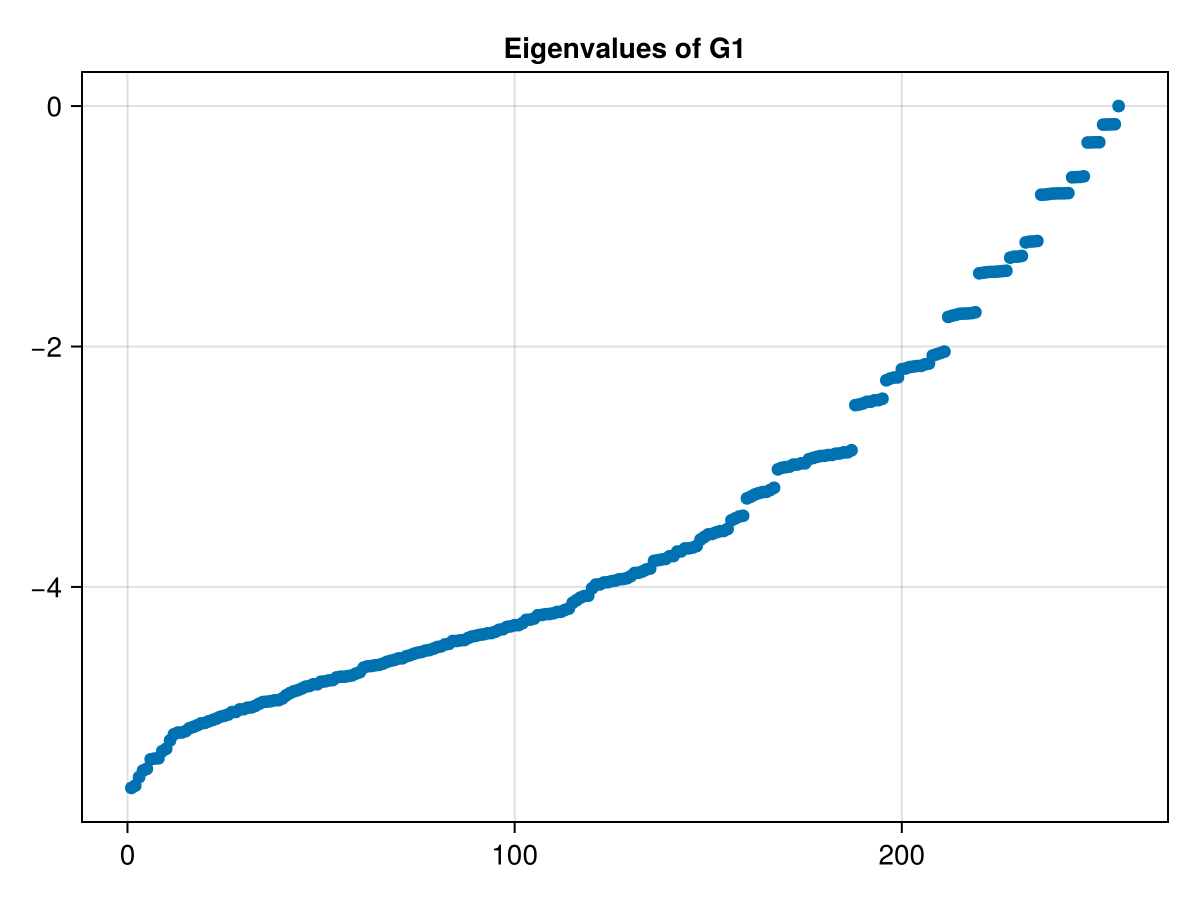

In [130]:
using LinearAlgebra
eig1 = eigvals(Matrix(G1))
eig2 = eigvals(Matrix(G2))
eig3 = eigvals(Matrix(G3))
fig = Figure()
ax = Axis(fig[1, 1], title = "Eigenvalues of G1")
scatter!(ax, eig1)
fig

In [128]:
fig = Figure(size = (900, 400))
ax1 = Axis(fig[1, 1], title = L"Eigenvalues of $\Delta_{diag}$", xlabel = L"Re(\lambda)", ylabel = L"Im(\lambda)")
for i in 1:length(eig1)
    scatter!(ax1, real(eig1[i]), imag(eig1[i]), color = :red)
end
ax2 = Axis(fig[1, 2], title = L"Eigenvalues of $\Delta_{lsq1}$", xlabel = L"Re(\lambda)", ylabel = L"Im(\lambda)")
for i in 1:length(eig2)
    scatter!(ax2, real(eig2[i]), imag(eig2[i]), color = :blue)
end
ax3 = Axis(fig[1, 3], title = L"Eigenvalues of $\Delta_{lsq2}$", xlabel = L"Re(\lambda)", ylabel = L"Im(\lambda)")
for i in 1:length(eig3)
    scatter!(ax3, real(eig3[i]), imag(eig3[i]), color = :green)
end
CairoMakie.save("results/laplacian/eigenvalues.pdf", fig)

CairoMakie.Screen{PDF}


In [120]:
eig3

256-element Vector{ComplexF64}:
     -5.394587527276039 + 0.0im
     -5.391584220300769 + 0.0im
     -5.370548502832602 + 0.0im
    -5.2410031494199885 + 0.0im
     -5.217467771786499 + 0.0im
     -5.122500552711753 + 0.0im
    -5.1205528529544235 - 0.01637630498660222im
    -5.1205528529544235 + 0.01637630498660222im
     -5.074737264144655 + 0.0im
     -5.040588779493065 + 0.0im
                        ⋮
    -0.3059636033627267 + 0.0im
    -0.3048928288022693 + 0.0im
    -0.3035770509841853 + 0.0im
    -0.3033959816386925 + 0.0im
    -0.1549984512316609 + 0.0im
   -0.15347994761762698 + 0.0im
    -0.1529522167997219 + 0.0im
    -0.1513818057801767 + 0.0im
 -7.265684724874303e-17 + 0.0im

In [115]:
star(mesh, 2, false)

256×256 Diagonal{Float64, Vector{Float64}}:
 270.44     ⋅        ⋅        ⋅     …     ⋅        ⋅        ⋅       ⋅ 
    ⋅    231.285     ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅     253.466     ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅     249.659        ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅     …     ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
   ⋮                                ⋱                              ⋮
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅           ⋅        ⋅        ⋅       ⋅ 
    ⋅       ⋅        ⋅        ⋅    